In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/sample_submission.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_49.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_90.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_77.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_66.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_54.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_42.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_81.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test/audio_72.wav
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final

In [2]:
import kagglehub, os

# Download latest version
path = kagglehub.competition_download('shl-hiring-assessment-2026')

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/shl-hiring-assessment-2026


In [3]:
for root, dirs, files in os.walk(path):
    print(root, "->", files[:5], f"({len(files)} files)")

/kaggle/input/competitions/shl-hiring-assessment-2026 -> [] (0 files)
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final -> ['sample_submission.csv', 'train.csv', 'test.csv'] (3 files)
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test -> ['audio_49.wav', 'audio_90.wav', 'audio_77.wav', 'audio_66.wav', 'audio_54.wav'] (216 files)
/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train -> ['audio_49.wav', 'audio_663.wav', 'audio_5059.wav', 'audio_90.wav', 'audio_581.wav'] (769 files)


In [4]:
import pandas as pd

In [5]:
train_df=pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train.csv")
train_df.head()

,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


In [6]:
test_df=pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv")
test_df.head()

,filename,label
0,audio_128.wav,-1
1,audio_156.wav,-1
2,audio_19.wav,-1
3,audio_108.wav,-1
4,audio_206.wav,-1


In [7]:
train_df.describe()

,label
count,769.000000
mean,3.313394
std,1.239000
min,0.000000
25%,2.500000
50%,3.000000
75%,4.000000
max,5.000000


In [8]:
train_df.shape

(769, 2)

In [9]:
train_df['label'].describe()

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64

In [10]:
print(train_df["filename"].duplicated().sum())

0


In [11]:
import os
audio_dir = "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train"

train_df["path"] = audio_dir + "/" + train_df["filename"]

In [12]:
print(train_df["path"].apply(os.path.exists).value_counts())

path
True    769
Name: count, dtype: int64


In [13]:
import torchaudio

wav, sr = torchaudio.load(train_df["path"].iloc[0])
print(wav.shape, sr, wav.shape[1] / sr, "seconds")
print("max amplitude:", wav.abs().max().item())

torch.Size([1, 968134]) 16000 60.508375 seconds
max amplitude: 0.477783203125


count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64
label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64


<Axes: >

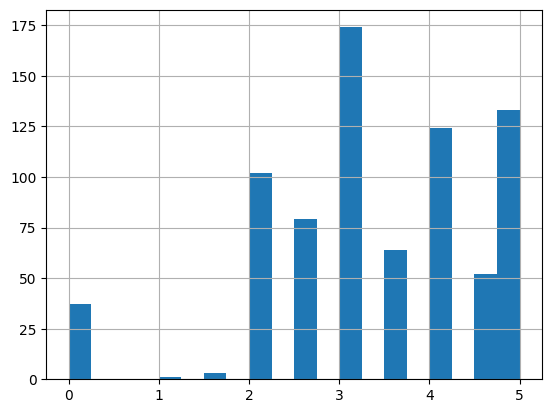

In [14]:
print(train_df["label"].describe())
print(train_df["label"].value_counts().sort_index())
train_df["label"].hist(bins=20)

In [15]:
import soundfile as sf, pandas as pd

rows = []
for f in train_df["path"]:
    info = sf.info(f)   
    rows.append((info.samplerate, info.channels, info.frames / info.samplerate))

meta = pd.DataFrame(rows, columns=["sr", "channels", "duration"])

In [16]:
print(meta["sr"].value_counts())
print(meta["channels"].value_counts())
print(meta["duration"].describe())
print(meta["duration"].quantile([0.05, 0.5, 0.95]))

sr
16000    769
Name: count, dtype: int64
channels
1    769
Name: count, dtype: int64
count    769.000000
mean      55.781067
std        7.908964
min       20.060000
25%       54.186687
50%       60.074688
75%       60.074688
max       61.040000
Name: duration, dtype: float64
0.05    43.212000
0.50    60.074688
0.95    60.167000
Name: duration, dtype: float64


In [17]:
train_df = pd.concat([train_df, meta], axis=1)
print(train_df[["duration", "label"]].corr())

          duration    label
duration   1.00000  0.08738
label      0.08738  1.00000


In [18]:
import torchaudio, numpy as np

stats = []
for f in train_df["path"].sample(300, random_state=0):
    try:
        w, _ = torchaudio.load(f)
        stats.append((w.abs().max().item(), w.pow(2).mean().sqrt().item()))
    except Exception as e:
        print("failed:", f, e)

s = pd.DataFrame(stats, columns=["peak", "rms"])
print(s.describe())

             peak         rms
count  300.000000  300.000000
mean     0.746491    0.060745
std      0.246814    0.026949
min      0.045685    0.004504
25%      0.615425    0.046044
50%      0.825226    0.058709
75%      0.945152    0.075024
max      1.000000    0.153744


In [19]:
import soundfile as sf
import numpy as np

TARGET_SR = 16000
MAX_SECONDS = 60

def load_audio(path):
    wav, sr = sf.read(path, dtype="float32")
    assert sr == TARGET_SR, f"unexpected sr {sr} in {path}"   # safety check
    if wav.ndim > 1:                                           # safety check, should never fire
        wav = wav.mean(axis=1)
    wav = wav[: TARGET_SR * MAX_SECONDS]                       # cap at 60 s
    peak = np.abs(wav).max()
    if peak > 0:
        wav = wav / peak                                       # peak normalise
    return wav

In [20]:
for i in range(3):
    w = load_audio(train_df["path"].iloc[i])
    print(w.shape, w.dtype, round(len(w) / TARGET_SR, 1), "s | max:", np.abs(w).max())

(960000,) float32 60.0 s | max: 1.0
(960000,) float32 60.0 s | max: 1.0
(960000,) float32 60.0 s | max: 1.0


In [21]:
bad = []
for f in train_df["path"].sample(300, random_state=0):
    try:
        w = load_audio(f)
        if len(w) < TARGET_SR * 0.5 or np.abs(w).max() == 0:
            bad.append(f)
    except Exception as e:
        bad.append((f, str(e)))
print(len(bad), "problem files out of 300")

0 problem files out of 300


In [22]:
import torch, numpy as np
from transformers import AutoFeatureExtractor, AutoModel
from tqdm.auto import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"
name = "microsoft/wavlm-base-plus"     # alternative: "facebook/wav2vec2-base"

fe = AutoFeatureExtractor.from_pretrained(name)
model = AutoModel.from_pretrained(name).to(device).eval()

def embed(path):
    wav = load_audio(path)
    inp = fe(wav, sampling_rate=16000, return_tensors="pt").to(device)
    with torch.no_grad():
        out = model(**inp, output_hidden_states=True)
    hs = torch.stack(out.hidden_states)            # (13, 1, T, 768)
    return hs.mean(dim=2).squeeze(1).cpu().numpy() # (13, 768)

# test on one file first
print(embed(train_df["path"].iloc[0]).shape)       # expect (13, 768)

feats = np.stack([embed(p) for p in tqdm(train_df["path"])])   # (N, 13, 768)
np.save("wavlm_train_feats.npy", feats)

preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6409: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


(13, 768)


  0%|          | 0/769 [00:00<?, ?it/s]

In [23]:
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from scipy.stats import pearsonr

y = train_df["label"].values   # use your score column name
kf = KFold(5, shuffle=True, random_state=42)

def cv_score(X, alpha=10):
    oof = np.zeros(len(y))
    for tr, va in kf.split(X):
        m = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
        m.fit(X[tr], y[tr])
        oof[va] = m.predict(X[va])
    oof = np.clip(oof, 0, 5)
    return np.sqrt(np.mean((y - oof) ** 2)), pearsonr(y, oof)[0]

# dumb baseline: always predict the mean
print("mean baseline RMSE:", np.sqrt(np.mean((y - y.mean()) ** 2)))

for layer in range(feats.shape[1]):
    rmse, pcc = cv_score(feats[:, layer, :])
    print(f"layer {layer:2d} | RMSE {rmse:.3f} | Pearson {pcc:.3f}")

mean baseline RMSE: 1.2381936808002134
layer  0 | RMSE 0.759 | Pearson 0.791
layer  1 | RMSE 0.725 | Pearson 0.816
layer  2 | RMSE 0.766 | Pearson 0.796
layer  3 | RMSE 0.750 | Pearson 0.806
layer  4 | RMSE 0.724 | Pearson 0.818
layer  5 | RMSE 0.666 | Pearson 0.846
layer  6 | RMSE 0.689 | Pearson 0.836
layer  7 | RMSE 0.634 | Pearson 0.862
layer  8 | RMSE 0.685 | Pearson 0.837
layer  9 | RMSE 0.683 | Pearson 0.839
layer 10 | RMSE 0.658 | Pearson 0.850
layer 11 | RMSE 0.653 | Pearson 0.851
layer 12 | RMSE 0.661 | Pearson 0.847


In [24]:
X_train = feats[:, 5:13, :].mean(axis=1)

results = {}
for a in [10, 100, 1000, 3000]:
    results[a] = cv_score(X_train, alpha=a)
    print(f"alpha {a:5d} | RMSE {results[a][0]:.3f} | Pearson {results[a][1]:.3f}")

best_alpha = min(results, key=lambda a: results[a][0])
print("best alpha:", best_alpha)

alpha    10 | RMSE 0.661 | Pearson 0.848
alpha   100 | RMSE 0.593 | Pearson 0.878
alpha  1000 | RMSE 0.603 | Pearson 0.875
alpha  3000 | RMSE 0.636 | Pearson 0.862
best alpha: 100


In [25]:
sub = pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/sample_submission.csv")
print(sub.columns.tolist())
print(sub.head())

test_df = pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv")      
test_dir = "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test"
test_df["path"] = test_dir + "/" + test_df["filename"]   
print("all test files exist:", test_df["path"].apply(os.path.exists).all())

['filename', 'label']
         filename  label
0   audio_804.wav     -1
1  audio_1028.wav     -1
2   audio_865.wav     -1
3   audio_774.wav     -1
4  audio_1138.wav     -1
all test files exist: True


In [26]:
test_feats = np.stack([embed(p) for p in tqdm(test_df["path"])])   # (M, 13, 768)
np.save("wavlm_test_feats.npy", test_feats)
X_test = test_feats[:, 5:13, :].mean(axis=1)

  0%|          | 0/216 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6409: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(


In [27]:
final = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha))
final.fit(X_train, y)
preds = np.clip(final.predict(X_test), 0, 5)

In [28]:
submission = pd.DataFrame({
    sub.columns[0]: test_df["filename"],
    sub.columns[1]: preds,
})


In [29]:
print("same shape as sample:", submission.shape == sub.shape)
print("same columns:", submission.columns.tolist() == sub.columns.tolist())
print("missing values:", submission.isna().sum().sum())
print("same IDs:", set(submission.iloc[:, 0]) == set(sub.iloc[:, 0]))
print(submission.iloc[:, 1].describe())

same shape as sample: False
same columns: True
missing values: 0
same IDs: False
count    216.000000
mean       3.297440
std        0.820902
min        1.673760
25%        2.727397
50%        3.151969
75%        3.789170
max        5.000000
Name: label, dtype: float64


In [30]:
print(submission.shape, sub.shape)
print(submission.iloc[:5, 0].tolist())
print(sub.iloc[:5, 0].tolist())

a = set(submission.iloc[:, 0]); b = set(sub.iloc[:, 0])
print("in mine not in sample:", len(a - b), list(a - b)[:3])
print("in sample not in mine:", len(b - a), list(b - a)[:3])

(216, 2) (204, 2)
['audio_128.wav', 'audio_156.wav', 'audio_19.wav', 'audio_108.wav', 'audio_206.wav']
['audio_804.wav', 'audio_1028.wav', 'audio_865.wav', 'audio_774.wav', 'audio_1138.wav']
in mine not in sample: 191 ['audio_131.wav', 'audio_56.wav', 'audio_177.wav']
in sample not in mine: 179 ['audio_1246.wav', 'audio_1102.wav', 'audio_1329.wav']


In [31]:
test_files = set(os.listdir("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test"))
csv_ids = set(pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv").iloc[:, 0])
sub_ids = set(sub.iloc[:, 0])

print("files in test folder:", len(test_files))
print("test.csv IDs found in folder:", len(csv_ids & test_files), "of", len(csv_ids))
print("sample IDs found in folder:", len(sub_ids & test_files), "of", len(sub_ids))

files in test folder: 216
test.csv IDs found in folder: 216 of 216
sample IDs found in folder: 25 of 204


In [32]:
tcsv = pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv")

print(submission.shape)                                          # (216, 2)
print(submission.columns.tolist() == sub.columns.tolist())       # True: same column names as the sample
print(set(submission.iloc[:, 0]) == set(tcsv.iloc[:, 0]))        # True: IDs match test.csv
print(submission.iloc[:, 0].is_unique)                           # True: no duplicate IDs
print(submission.isna().sum().sum())                             # 0
print(submission.iloc[:, 1].between(0, 5).all())                 # True

(216, 2)
True
True
True
0
True


In [33]:
submission.to_csv("submission.csv", index=False)

In [34]:
from sklearn.svm import SVR

def cv_oof(make_model, X):
    oof = np.zeros(len(y))
    for tr, va in kf.split(X):
        m = make_model(); m.fit(X[tr], y[tr]); oof[va] = m.predict(X[va])
    oof = np.clip(oof, 0, 5)
    return oof, np.sqrt(np.mean((y - oof) ** 2)), pearsonr(y, oof)[0]

X_avg = feats[:, 5:13, :].mean(axis=1)
X_cat = np.concatenate([feats[:, 5, :], feats[:, 7, :], feats[:, 11, :]], axis=1)

candidates = {}
for a in [100, 300, 1000, 3000]:
    candidates[f"ridge avg a={a}"] = (lambda a=a: make_pipeline(StandardScaler(), Ridge(alpha=a)), X_avg)
    candidates[f"ridge cat a={a*3}"] = (lambda a=a: make_pipeline(StandardScaler(), Ridge(alpha=a*3)), X_cat)
for C in [1, 3, 10]:
    candidates[f"svr avg C={C}"] = (lambda C=C: make_pipeline(StandardScaler(), SVR(C=C)), X_avg)

for name, (mk, X) in candidates.items():
    _, r, p = cv_oof(mk, X)
    print(f"{name:20s} RMSE {r:.3f} | Pearson {p:.3f}")

ridge avg a=100      RMSE 0.593 | Pearson 0.878
ridge cat a=300      RMSE 0.563 | Pearson 0.891
ridge avg a=300      RMSE 0.589 | Pearson 0.880
ridge cat a=900      RMSE 0.569 | Pearson 0.889
ridge avg a=1000     RMSE 0.603 | Pearson 0.875
ridge cat a=3000     RMSE 0.595 | Pearson 0.879
ridge avg a=3000     RMSE 0.636 | Pearson 0.862
ridge cat a=9000     RMSE 0.643 | Pearson 0.860
svr avg C=1          RMSE 0.575 | Pearson 0.887
svr avg C=3          RMSE 0.556 | Pearson 0.894
svr avg C=10         RMSE 0.552 | Pearson 0.896


In [35]:
candidates = {}
for C in [10, 30, 100]:
    candidates[f"svr avg C={C}"] = (lambda C=C: make_pipeline(StandardScaler(), SVR(C=C)), X_avg)
    candidates[f"svr cat C={C}"] = (lambda C=C: make_pipeline(StandardScaler(), SVR(C=C)), X_cat)
for a in [30, 100]:
    candidates[f"ridge cat a={a}"] = (lambda a=a: make_pipeline(StandardScaler(), Ridge(alpha=a)), X_cat)
for eps in [0.05, 0.2]:
    candidates[f"svr avg C=10 eps={eps}"] = (lambda e=eps: make_pipeline(StandardScaler(), SVR(C=10, epsilon=e)), X_avg)

for name, (mk, X) in candidates.items():
    _, r, p = cv_oof(mk, X)
    print(f"{name:22s} RMSE {r:.3f} | Pearson {p:.3f}")

svr avg C=10           RMSE 0.552 | Pearson 0.896
svr cat C=10           RMSE 0.548 | Pearson 0.898
svr avg C=30           RMSE 0.552 | Pearson 0.896
svr cat C=30           RMSE 0.548 | Pearson 0.898
svr avg C=100          RMSE 0.552 | Pearson 0.896
svr cat C=100          RMSE 0.548 | Pearson 0.898
ridge cat a=30         RMSE 0.593 | Pearson 0.879
ridge cat a=100        RMSE 0.572 | Pearson 0.887
svr avg C=10 eps=0.05  RMSE 0.549 | Pearson 0.897
svr avg C=10 eps=0.2   RMSE 0.558 | Pearson 0.894


In [36]:
oof_svr, r1, p1 = cv_oof(lambda: make_pipeline(StandardScaler(), SVR(C=10)), X_avg)
oof_rdg, r2, p2 = cv_oof(lambda: make_pipeline(StandardScaler(), Ridge(alpha=300)), X_cat)

blend = (oof_svr + oof_rdg) / 2
print("blend RMSE", np.sqrt(np.mean((y - blend) ** 2)), "| Pearson", pearsonr(y, blend)[0])

blend RMSE 0.5394515682616678 | Pearson 0.9007138354355205


In [37]:
# test features, built the same way as train
Xt_avg = test_feats[:, 5:13, :].mean(axis=1)
Xt_cat = np.concatenate([test_feats[:, 5, :], test_feats[:, 7, :], test_feats[:, 11, :]], axis=1)

svr = make_pipeline(StandardScaler(), SVR(C=10)).fit(X_avg, y)
rdg = make_pipeline(StandardScaler(), Ridge(alpha=300)).fit(X_cat, y)

preds = np.clip((svr.predict(Xt_avg) + rdg.predict(Xt_cat)) / 2, 0, 5)

submission1 = pd.DataFrame({
    sub.columns[0]: test_df["filename"],
    sub.columns[1]: preds,
})

In [38]:
submission1.to_csv("submission.csv", index=False)

In [39]:
print(submission1.shape, submission1.isna().sum().sum(), submission1.iloc[:, 1].describe())

(216, 2) 0 count    216.000000
mean       3.303321
std        0.781250
min        1.557440
25%        2.785365
50%        3.204435
75%        3.730909
max        5.000000
Name: label, dtype: float64


In [40]:
import numpy as np

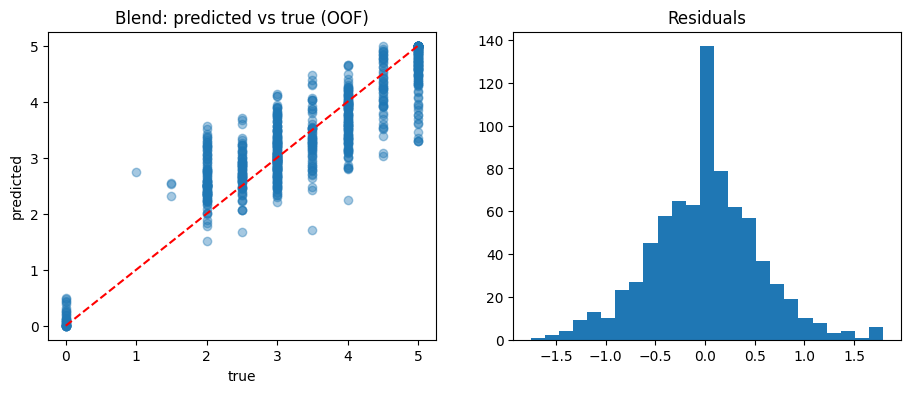

In [41]:
import matplotlib.pyplot as plt
blend = np.clip(blend, 0, 5)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y, blend, alpha=0.4); ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set_xlabel("true"); ax[0].set_ylabel("predicted"); ax[0].set_title("Blend: predicted vs true (OOF)")
ax[1].hist(y - blend, bins=25); ax[1].set_title("Residuals")
plt.show()

In [42]:
import soundfile as sf
def dur(p):
    i = sf.info(p); return i.frames / i.samplerate
test_df["duration"] = test_df["path"].apply(dur)

In [43]:
import time, torch
from transformers import pipeline
from tqdm.auto import tqdm

asr = pipeline("automatic-speech-recognition", model="openai/whisper-small",
               device=0, torch_dtype=torch.float16, chunk_length_s=30)

def transcribe(paths):
    clips = [{"raw": load_audio(p), "sampling_rate": 16000} for p in paths]
    out = asr(clips, batch_size=8, generate_kwargs={"language": "en"})
    return [o["text"].strip() for o in out]

t0 = time.time()
sample = train_df.iloc[:20].copy()
sample["text"] = transcribe(sample["path"].tolist())
print("seconds for 20 clips:", round(time.time() - t0, 1))
for t, s in zip(sample["text"][:6], sample["label"][:6]):
    print(f"[{s:.1f}] {t[:200]}")

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

...

added_tokens.json:   0%|          | 0.00/34.6k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.19k [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on it's own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).
[transformers] Passing `generation_config` together with generation-related arguments=({'begin_suppress_tokens', 'suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer WhisperTokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE 

seconds for 20 clips: 57.3
[3.0] The playground is very, very beautiful and fun. There are places like the merry-go-round, the swing. The students usually enjoy the swing. It has to be like, it's more like a game of pair, because one
[3.0] The scene of a school playground. Our playground looks like a very big playground having a more greenery trees. In which we students like to garden more trees to have fresh air and all having fresh ox
[3.5] My favorite place to visit is the beach. I love the sound of the waves crashing against the shore. The feeling of the sand between my toys and the small smell of the salt water. I love the fact that t
[2.0] Once upon a time, we, with five friends, went on a trip with a travel agent on a monality. And we stayed at a resort. And we stayed around. We stayed at a resort. And after that, when we checked in in
[2.0] Well, when I was a child, I remember I went to the kindergarten and I liked to play ground. I remember there are a lot of kids, a lot, well

In [44]:
def run(df, name):
    texts = []
    for i in tqdm(range(0, len(df), 64)):
        texts += transcribe(df["path"].iloc[i:i+64].tolist())
    df["text"] = texts
    df[["filename", "text"]].to_csv(f"{name}_transcripts.csv", index=False)

run(train_df, "train")
run(test_df, "test")

  0%|          | 0/13 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  0%|          | 0/4 [00:00<?, ?it/s]

In [45]:
from sentence_transformers import SentenceTransformer
import re
from transformers import GPT2LMHeadModel, GPT2TokenizerFast

st = SentenceTransformer("all-mpnet-base-v2", device="cuda")
T_train = st.encode(train_df["text"].tolist(), batch_size=32, show_progress_bar=True)
T_test  = st.encode(test_df["text"].tolist(),  batch_size=32, show_progress_bar=True)

tok = GPT2TokenizerFast.from_pretrained("gpt2")
lm = GPT2LMHeadModel.from_pretrained("gpt2").cuda().eval()

def ppl(text):
    ids = tok(text, return_tensors="pt", truncation=True, max_length=512).input_ids.cuda()
    if ids.shape[1] < 2: return 0.0
    with torch.no_grad():
        return lm(ids, labels=ids).loss.item()

def hand(df):
    rows = []
    for t, d in zip(df["text"], df["duration"]):
        w = re.findall(r"[a-z']+", t.lower()); n = len(w)
        rows.append([n, n / max(d, 1), len(set(w)) / max(n, 1),
                     np.mean([len(x) for x in w]) if n else 0, ppl(t) if n else 0])
    return np.array(rows)

H_train, H_test = hand(train_df), hand(test_df)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


In [46]:
X_text = np.concatenate([T_train, H_train], axis=1)
oof_txt, r3, p3 = cv_oof(lambda: make_pipeline(StandardScaler(), Ridge(alpha=1000)), X_text)
print("text only:", r3, p3)

from sklearn.linear_model import LinearRegression
S = np.c_[oof_svr, oof_rdg, oof_txt]
lr = LinearRegression(positive=True).fit(S, y)
print("weights:", lr.coef_, "intercept:", lr.intercept_)

blend3 = np.clip(S.mean(axis=1), 0, 5)       # simple average, safer than fitted weights
print("3-way avg RMSE", np.sqrt(np.mean((y - blend3) ** 2)), "| Pearson", pearsonr(y, blend3)[0])

text only: 1.0080161413297948 0.5807315531299427
weights: [0.58868799 0.3972263  0.14015784] intercept: -0.4159406751363872
3-way avg RMSE 0.6017199221827105 | Pearson 0.8930261397095504


In [47]:
from sklearn.model_selection import cross_val_predict

S2 = np.c_[oof_svr, oof_rdg]
S3 = np.c_[oof_svr, oof_rdg, oof_txt]
for name, S in [("audio only", S2), ("audio + text", S3)]:
    p = np.clip(cross_val_predict(LinearRegression(), S, y, cv=KFold(5, shuffle=True, random_state=1)), 0, 5)
    print(name, "RMSE", np.sqrt(np.mean((y - p) ** 2)), "| Pearson", pearsonr(y, p)[0])

audio only RMSE 0.5384567476316994 | Pearson 0.9005606052016942
audio + text RMSE 0.5318284476320109 | Pearson 0.9031369366923655


In [48]:
stack = LinearRegression().fit(S3, y)
txt = make_pipeline(StandardScaler(), Ridge(alpha=1000)).fit(X_text, y)
Xt_text = np.concatenate([T_test, H_test], axis=1)

P = np.c_[svr.predict(Xt_avg), rdg.predict(Xt_cat), txt.predict(Xt_text)]
preds = np.clip(stack.predict(P), 0, 5)

In [49]:
submission2 = pd.DataFrame({
    sub.columns[0]: test_df["filename"],
    sub.columns[1]: preds,
})
submission2.to_csv("submission2.csv", index=False)

# quick checks
print(submission2.shape)                                   # (216, 2)
print(submission2.isna().sum().sum())                      # 0
print(set(submission2.iloc[:, 0]) == set(tcsv.iloc[:, 0])) # True 
print(submission2.iloc[:, 1].describe())

(216, 2)
0
True
count    216.000000
mean       3.264792
std        0.825660
min        1.455480
25%        2.690412
50%        3.167194
75%        3.669756
max        5.000000
Name: label, dtype: float64


In [50]:
import os, numpy as np, pandas as pd, soundfile as sf, torch
from tqdm.auto import tqdm
from scipy.stats import pearsonr
from sklearn.model_selection import KFold
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR

device = "cuda" if torch.cuda.is_available() else "cpu"
base = "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"

train_df = pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/train.csv")
train_df["path"] = base + "/train/" + train_df["filename"]
test_df = pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv")
test_df["path"] = base + "/test/" + test_df["filename"]
sub = pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/sample_submission.csv")
y = train_df["label"].values

TARGET_SR, MAX_SECONDS = 16000, 60
def load_audio(path):
    wav, sr = sf.read(path, dtype="float32")
    assert sr == TARGET_SR
    if wav.ndim > 1: wav = wav.mean(axis=1)
    wav = wav[: TARGET_SR * MAX_SECONDS]
    peak = np.abs(wav).max()
    return wav / peak if peak > 0 else wav

kf = KFold(5, shuffle=True, random_state=42)

def cv_oof(make_model, X):
    oof = np.zeros(len(y))
    for tr, va in kf.split(X):
        m = make_model(); m.fit(X[tr], y[tr]); oof[va] = m.predict(X[va])
    oof = np.clip(oof, 0, 5)
    return oof, np.sqrt(np.mean((y - oof) ** 2)), pearsonr(y, oof)[0]

def cv_score(X, alpha=10):
    _, r, p = cv_oof(lambda: make_pipeline(StandardScaler(), Ridge(alpha=alpha)), X)
    return r, p

In [51]:
os.listdir("/kaggle/working")

['wavlm_test_feats.npy',
 'train_transcripts.csv',
 'wavlm_train_feats.npy',
 'submission.csv',
 'submission2.csv',
 'test_transcripts.csv',
 '__notebook__.ipynb']

In [52]:
from transformers import AutoFeatureExtractor, AutoModel

fe_L = AutoFeatureExtractor.from_pretrained("microsoft/wavlm-large")
model_L = AutoModel.from_pretrained("microsoft/wavlm-large").to(device).eval().half()

def embed2(path):
    wav = load_audio(path)
    inp = fe_L(wav, sampling_rate=16000, return_tensors="pt")
    with torch.no_grad():
        out = model_L(inp["input_values"].to(device).half(), output_hidden_states=True)
    hs = torch.stack(out.hidden_states).float()
    return torch.cat([hs.mean(dim=2), hs.std(dim=2)], dim=-1).squeeze(1).cpu().numpy()   # (25, 2048)

print(embed2(train_df["path"].iloc[0]).shape)     # expect (25, 2048)

feats_L = np.stack([embed2(p) for p in tqdm(train_df["path"])])
np.save("wavlmL_train.npy", feats_L)
test_feats_L = np.stack([embed2(p) for p in tqdm(test_df["path"])])
np.save("wavlmL_test.npy", test_feats_L)

preprocessor_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.22k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.26GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/488 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

model.safetensors: downloading bytes:           |  0.00B            

(25, 2048)


  0%|          | 0/769 [00:00<?, ?it/s]

  0%|          | 0/216 [00:00<?, ?it/s]

In [53]:
feats_L = np.stack([embed2(p) for p in tqdm(train_df["path"])])
np.save("wavlmL_train.npy", feats_L)

test_feats_L = np.stack([embed2(p) for p in tqdm(test_df["path"])])
np.save("wavlmL_test.npy", test_feats_L)
print(feats_L.shape, test_feats_L.shape)

  0%|          | 0/769 [00:00<?, ?it/s]

  0%|          | 0/216 [00:00<?, ?it/s]

(769, 25, 2048) (216, 25, 2048)


In [54]:
for layer in range(0, 25, 2):
    r, p = cv_score(feats_L[:, layer, :], alpha=1000)
    print(f"layer {layer:2d} | RMSE {r:.3f} | Pearson {p:.3f}")

layer  0 | RMSE 0.720 | Pearson 0.815
layer  2 | RMSE 0.679 | Pearson 0.837
layer  4 | RMSE 0.665 | Pearson 0.845
layer  6 | RMSE 0.645 | Pearson 0.855
layer  8 | RMSE 0.605 | Pearson 0.874
layer 10 | RMSE 0.574 | Pearson 0.887
layer 12 | RMSE 0.567 | Pearson 0.890
layer 14 | RMSE 0.563 | Pearson 0.891
layer 16 | RMSE 0.551 | Pearson 0.896
layer 18 | RMSE 0.545 | Pearson 0.899
layer 20 | RMSE 0.549 | Pearson 0.897
layer 22 | RMSE 0.560 | Pearson 0.893
layer 24 | RMSE 0.578 | Pearson 0.886


In [55]:
good = [14, 16, 18, 20, 22]
XL_avg = feats_L[:, good, :].mean(axis=1)                                   # (N, 2048)
XL_cat = np.concatenate([feats_L[:, l, :] for l in [14, 18, 22]], axis=1)   # (N, 6144)

for C in [3, 10, 30]:
    _, r, p = cv_oof(lambda C=C: make_pipeline(StandardScaler(), SVR(C=C)), XL_avg)
    print(f"svr avg C={C} | RMSE {r:.3f} | Pearson {p:.3f}")
for a in [1000, 3000, 10000]:
    _, r, p = cv_oof(lambda a=a: make_pipeline(StandardScaler(), Ridge(alpha=a)), XL_avg)
    print(f"ridge avg a={a} | RMSE {r:.3f} | Pearson {p:.3f}")
for a in [3000, 10000, 30000]:
    _, r, p = cv_oof(lambda a=a: make_pipeline(StandardScaler(), Ridge(alpha=a)), XL_cat)
    print(f"ridge cat a={a} | RMSE {r:.3f} | Pearson {p:.3f}")

svr avg C=3 | RMSE 0.541 | Pearson 0.900
svr avg C=10 | RMSE 0.538 | Pearson 0.901
svr avg C=30 | RMSE 0.538 | Pearson 0.901
ridge avg a=1000 | RMSE 0.550 | Pearson 0.897
ridge avg a=3000 | RMSE 0.574 | Pearson 0.888
ridge avg a=10000 | RMSE 0.628 | Pearson 0.868
ridge cat a=3000 | RMSE 0.542 | Pearson 0.900
ridge cat a=10000 | RMSE 0.568 | Pearson 0.891
ridge cat a=30000 | RMSE 0.615 | Pearson 0.874


In [56]:
oof_svrL, *_ = cv_oof(lambda: make_pipeline(StandardScaler(), SVR(C=10)), XL_avg)
oof_rdgL, *_ = cv_oof(lambda: make_pipeline(StandardScaler(), Ridge(alpha=3000)), XL_cat)

def report(name, oof):
    oof = np.clip(oof, 0, 5)
    print(f"{name:28s} RMSE {np.sqrt(np.mean((y - oof) ** 2)):.3f} | Pearson {pearsonr(y, oof)[0]:.3f}")

report("large only (2 models)", (oof_svrL + oof_rdgL) / 2)
report("base only (2 models)", (oof_svr + oof_rdg) / 2)
report("all 4 equal", (oof_svr + oof_rdg + oof_svrL + oof_rdgL) / 4)
report("large-heavy 4", 0.2 * oof_svr + 0.2 * oof_rdg + 0.3 * oof_svrL + 0.3 * oof_rdgL)

large only (2 models)        RMSE 0.529 | Pearson 0.905
base only (2 models)         RMSE 0.539 | Pearson 0.901
all 4 equal                  RMSE 0.523 | Pearson 0.908
large-heavy 4                RMSE 0.522 | Pearson 0.908


In [57]:
XLt_avg = test_feats_L[:, good, :].mean(axis=1)
XLt_cat = np.concatenate([test_feats_L[:, l, :] for l in [14, 18, 22]], axis=1)

svr  = make_pipeline(StandardScaler(), SVR(C=10)).fit(X_avg, y)
rdg  = make_pipeline(StandardScaler(), Ridge(alpha=300)).fit(X_cat, y)
svrL = make_pipeline(StandardScaler(), SVR(C=10)).fit(XL_avg, y)
rdgL = make_pipeline(StandardScaler(), Ridge(alpha=3000)).fit(XL_cat, y)

preds = np.clip((svr.predict(Xt_avg) + rdg.predict(Xt_cat)
                 + svrL.predict(XLt_avg) + rdgL.predict(XLt_cat)) / 4, 0, 5)

submission = pd.DataFrame({sub.columns[0]: test_df["filename"], sub.columns[1]: preds})
submission.to_csv("submission.csv", index=False)
print(submission.shape, submission.isna().sum().sum(), submission.iloc[:, 1].describe())

(216, 2) 0 count    216.000000
mean       3.322589
std        0.770083
min        1.704082
25%        2.775201
50%        3.227056
75%        3.714738
max        5.000000
Name: label, dtype: float64


In [58]:
import numpy as np

In [59]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict

blend4 = np.clip((oof_svr + oof_rdg + oof_svrL + oof_rdgL) / 4, 0, 5)
slope, intercept = np.polyfit(blend4, y, 1)
print("slope", slope, "intercept", intercept)      # slope well above 1 = compressed predictions

cal = cross_val_predict(LinearRegression(), blend4.reshape(-1, 1), y,
                        cv=KFold(5, shuffle=True, random_state=1))
cal = np.clip(cal, 0, 5)
print("before RMSE", np.sqrt(np.mean((y - blend4) ** 2)), "| after", np.sqrt(np.mean((y - cal) ** 2)))

slope 1.0565553288733338 intercept -0.18552968285728869
before RMSE 0.5229398971580113 | after 0.5194063951440804


/tmp/ipykernel_23/2746327087.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(pd.Series(np.abs(res)).groupby(pd.cut(y, [0, 2, 3, 4, 5])).mean())


(0, 2]    0.672933
(2, 3]    0.322211
(3, 4]    0.407065
(4, 5]    0.381439
dtype: float64
corr(abs err, duration): -0.17206149276320434


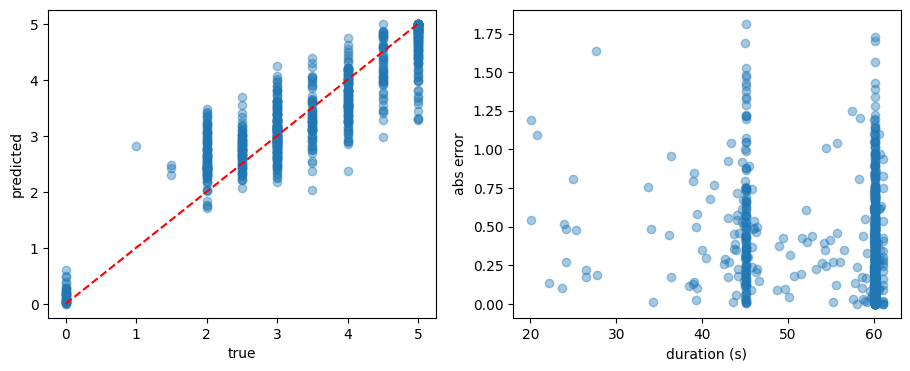

In [60]:
import matplotlib.pyplot as plt

if "duration" not in train_df.columns:
    train_df["duration"] = train_df["path"].apply(lambda p: sf.info(p).frames / sf.info(p).samplerate)

res = y - blend4
print(pd.Series(np.abs(res)).groupby(pd.cut(y, [0, 2, 3, 4, 5])).mean())
print("corr(abs err, duration):", np.corrcoef(np.abs(res), train_df["duration"])[0, 1])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(y, blend4, alpha=0.4); ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set_xlabel("true"); ax[0].set_ylabel("predicted")
ax[1].scatter(train_df["duration"], np.abs(res), alpha=0.4)
ax[1].set_xlabel("duration (s)"); ax[1].set_ylabel("abs error")
plt.show()

In [61]:
import gc
for v in ["model_L", "mdl_B"]:
    if v in globals():
        del globals()[v]
gc.collect(); torch.cuda.empty_cache()

from transformers import AutoFeatureExtractor, AutoModel

def make_embedder(name):
    fe = AutoFeatureExtractor.from_pretrained(name)
    mdl = AutoModel.from_pretrained(name).to(device).eval().half()
    def emb(path):
        wav = load_audio(path)
        x = fe(wav, sampling_rate=16000, return_tensors="pt")["input_values"].to(device).half()
        with torch.no_grad():
            hs = torch.stack(mdl(x, output_hidden_states=True).hidden_states).float()
        return torch.cat([hs.mean(dim=2), hs.std(dim=2)], dim=-1).squeeze(1).cpu().numpy()
    return emb

emb_H = make_embedder("facebook/hubert-large-ll60k")
print(emb_H(train_df["path"].iloc[0]).shape)          # expect (25, 2048)

feats_H = np.stack([emb_H(p) for p in tqdm(train_df["path"])])
np.save("hubert_train.npy", feats_H)
test_feats_H = np.stack([emb_H(p) for p in tqdm(test_df["path"])])
np.save("hubert_test.npy", test_feats_H)

preprocessor_config.json:   0%|          | 0.00/212 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.26GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/422 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

model.safetensors: downloading bytes:           |  0.00B            

(25, 2048)


  0%|          | 0/769 [00:00<?, ?it/s]

  0%|          | 0/216 [00:00<?, ?it/s]

In [62]:
for layer in range(0, 25, 2):
    r, p = cv_score(feats_H[:, layer, :], alpha=1000)
    print(f"layer {layer:2d} | RMSE {r:.3f} | Pearson {p:.3f}")

layer  0 | RMSE 0.724 | Pearson 0.812
layer  2 | RMSE 0.684 | Pearson 0.835
layer  4 | RMSE 0.684 | Pearson 0.835
layer  6 | RMSE 0.665 | Pearson 0.845
layer  8 | RMSE 0.659 | Pearson 0.848
layer 10 | RMSE 0.622 | Pearson 0.866
layer 12 | RMSE 0.594 | Pearson 0.878
layer 14 | RMSE 0.583 | Pearson 0.884
layer 16 | RMSE 0.582 | Pearson 0.884
layer 18 | RMSE 0.584 | Pearson 0.883
layer 20 | RMSE 0.591 | Pearson 0.879
layer 22 | RMSE 0.580 | Pearson 0.885
layer 24 | RMSE 0.599 | Pearson 0.876


In [63]:
goodH = [14, 16, 18, 20, 22]          # change after looking at the sweep
XH_avg = feats_H[:, goodH, :].mean(axis=1)
XH_cat = np.concatenate([feats_H[:, l, :] for l in goodH[::2]], axis=1)

for C in [3, 10, 30]:
    _, r, p = cv_oof(lambda C=C: make_pipeline(StandardScaler(), SVR(C=C)), XH_avg)
    print(f"svr C={C} | RMSE {r:.3f} | Pearson {p:.3f}")
for a in [1000, 3000, 10000]:
    _, r, p = cv_oof(lambda a=a: make_pipeline(StandardScaler(), Ridge(alpha=a)), XH_cat)
    print(f"ridge cat a={a} | RMSE {r:.3f} | Pearson {p:.3f}")

# use the best settings from the printout
oof_svrH, *_ = cv_oof(lambda: make_pipeline(StandardScaler(), SVR(C=10)), XH_avg)
oof_rdgH, *_ = cv_oof(lambda: make_pipeline(StandardScaler(), Ridge(alpha=3000)), XH_cat)

svr C=3 | RMSE 0.564 | Pearson 0.891
svr C=10 | RMSE 0.555 | Pearson 0.894
svr C=30 | RMSE 0.555 | Pearson 0.894
ridge cat a=1000 | RMSE 0.556 | Pearson 0.894
ridge cat a=3000 | RMSE 0.569 | Pearson 0.889
ridge cat a=10000 | RMSE 0.604 | Pearson 0.875


In [64]:
import torch.nn as nn

class LayerMix(nn.Module):
    def __init__(self, n_layers, dim):
        super().__init__()
        self.w = nn.Parameter(torch.zeros(n_layers))        # learned weights over layers
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(dim, 256), nn.ReLU(),
                                  nn.Dropout(0.2), nn.Linear(256, 1))
    def forward(self, x):                                   # x: (B, L, D)
        x = (x * torch.softmax(self.w, 0)[None, :, None]).sum(1)
        return self.head(x).squeeze(-1)

def fit_mix(Xtr, ytr, Xte, epochs=60, lr=1e-3, wd=1e-2, seed=0):
    torch.manual_seed(seed)
    mu, sd = Xtr.mean(0, keepdims=True), Xtr.std(0, keepdims=True) + 1e-6
    Xtr_t = torch.tensor((Xtr - mu) / sd, dtype=torch.float32, device=device)
    Xte_t = torch.tensor((Xte - mu) / sd, dtype=torch.float32, device=device)
    ym, ys = ytr.mean(), ytr.std()
    ytr_t = torch.tensor((ytr - ym) / ys, dtype=torch.float32, device=device)

    model = LayerMix(Xtr.shape[1], Xtr.shape[2]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t), device=device)
        for i in range(0, len(perm), 32):
            idx = perm[i:i + 32]
            loss = nn.functional.mse_loss(model(Xtr_t[idx]), ytr_t[idx])
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
    model.eval()
    with torch.no_grad():
        pred = model(Xte_t).cpu().numpy()
    return pred * ys + ym

XM = feats_L[:, 8:25, :]                       # (N, 17, 2048)
oof_mix = np.zeros(len(y))
for tr, va in kf.split(XM):
    oof_mix[va] = np.mean([fit_mix(XM[tr], y[tr], XM[va], seed=s) for s in range(2)], axis=0)
oof_mix = np.clip(oof_mix, 0, 5)
print("layer-mix RMSE", np.sqrt(np.mean((y - oof_mix) ** 2)), "| Pearson", pearsonr(y, oof_mix)[0])

layer-mix RMSE 0.5324859323116741 | Pearson 0.9028126156849143


In [65]:
def report(name, oof):
    oof = np.clip(oof, 0, 5)
    print(f"{name:30s} RMSE {np.sqrt(np.mean((y - oof) ** 2)):.3f} | Pearson {pearsonr(y, oof)[0]:.3f}")

report("current 4-model", (oof_svr + oof_rdg + oof_svrL + oof_rdgL) / 4)
report("+ hubert (6 models)", (oof_svr + oof_rdg + oof_svrL + oof_rdgL + oof_svrH + oof_rdgH) / 6)
report("+ hubert + layer-mix (7)", (oof_svr + oof_rdg + oof_svrL + oof_rdgL + oof_svrH + oof_rdgH + oof_mix) / 7)
report("large + hubert + mix (5)", (oof_svrL + oof_rdgL + oof_svrH + oof_rdgH + oof_mix) / 5)

current 4-model                RMSE 0.523 | Pearson 0.908
+ hubert (6 models)            RMSE 0.522 | Pearson 0.908
+ hubert + layer-mix (7)       RMSE 0.519 | Pearson 0.909
large + hubert + mix (5)       RMSE 0.521 | Pearson 0.909


In [66]:
XHt_avg = test_feats_H[:, goodH, :].mean(axis=1)
XHt_cat = np.concatenate([test_feats_H[:, l, :] for l in goodH[::2]], axis=1)

svrH = make_pipeline(StandardScaler(), SVR(C=10)).fit(XH_avg, y)
rdgH = make_pipeline(StandardScaler(), Ridge(alpha=3000)).fit(XH_cat, y)
svrL = make_pipeline(StandardScaler(), SVR(C=10)).fit(XL_avg, y)
rdgL = make_pipeline(StandardScaler(), Ridge(alpha=3000)).fit(XL_cat, y)
svr  = make_pipeline(StandardScaler(), SVR(C=10)).fit(X_avg, y)
rdg  = make_pipeline(StandardScaler(), Ridge(alpha=300)).fit(X_cat, y)

XMt = test_feats_L[:, 8:25, :]
pred_mix = np.mean([fit_mix(XM, y, XMt, seed=s) for s in range(3)], axis=0)

P = np.c_[svr.predict(Xt_avg), rdg.predict(Xt_cat),
          svrL.predict(XLt_avg), rdgL.predict(XLt_cat),
          svrH.predict(XHt_avg), rdgH.predict(XHt_cat),
          pred_mix]
preds = np.clip(P.mean(axis=1), 0, 5)

# optional calibration (only if step 1 helped):
# cal_model = LinearRegression().fit(blend_oof.reshape(-1, 1), y)   # blend_oof = the OOF average of the SAME models in P
# preds = np.clip(cal_model.predict(preds.reshape(-1, 1)), 0, 5)

submission = pd.DataFrame({sub.columns[0]: test_df["filename"], sub.columns[1]: preds})
submission.to_csv("submission.csv", index=False)
print(submission.shape, submission.isna().sum().sum(), submission.iloc[:, 1].describe())

(216, 2) 0 count    216.000000
mean       3.317408
std        0.766285
min        1.739022
25%        2.771858
50%        3.216941
75%        3.743359
max        5.000000
Name: label, dtype: float64


In [67]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_predict

oof_list = [oof_svr, oof_rdg, oof_svrL, oof_rdgL, oof_svrH, oof_rdgH, oof_mix]
blend_oof = np.clip(np.mean(oof_list, axis=0), 0, 5)

rmse_raw = np.sqrt(np.mean((y - blend_oof) ** 2))
slope, intercept = np.polyfit(blend_oof, y, 1)

cal_cv = cross_val_predict(LinearRegression(), blend_oof.reshape(-1, 1), y,
                           cv=KFold(5, shuffle=True, random_state=1))
cal_cv = np.clip(cal_cv, 0, 5)
rmse_cal = np.sqrt(np.mean((y - cal_cv) ** 2))

print(f"slope {slope:.3f} | RMSE raw {rmse_raw:.4f} | RMSE calibrated (nested CV) {rmse_cal:.4f}")
use_cal = (slope > 1.03) and (rmse_raw - rmse_cal >= 0.005)
print("apply calibration:", use_cal)

slope 1.059 | RMSE raw 0.5188 | RMSE calibrated (nested CV) 0.5150
apply calibration: False


In [68]:
svr  = make_pipeline(StandardScaler(), SVR(C=10)).fit(X_avg, y)
rdg  = make_pipeline(StandardScaler(), Ridge(alpha=300)).fit(X_cat, y)
svrL = make_pipeline(StandardScaler(), SVR(C=10)).fit(XL_avg, y)
rdgL = make_pipeline(StandardScaler(), Ridge(alpha=3000)).fit(XL_cat, y)
svrH = make_pipeline(StandardScaler(), SVR(C=10)).fit(XH_avg, y)
rdgH = make_pipeline(StandardScaler(), Ridge(alpha=3000)).fit(XH_cat, y)

XMt = test_feats_L[:, 8:25, :]
pred_mix = np.mean([fit_mix(XM, y, XMt, seed=s) for s in range(3)], axis=0)

P = np.c_[svr.predict(Xt_avg), rdg.predict(Xt_cat),
          svrL.predict(XLt_avg), rdgL.predict(XLt_cat),
          svrH.predict(XHt_avg), rdgH.predict(XHt_cat),
          pred_mix]
preds = np.clip(P.mean(axis=1), 0, 5)

if use_cal:
    cal_model = LinearRegression().fit(blend_oof.reshape(-1, 1), y)
    preds = np.clip(cal_model.predict(preds.reshape(-1, 1)), 0, 5)

In [69]:
tcsv = pd.read_csv("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final/test.csv")

submission = pd.DataFrame({sub.columns[0]: test_df["filename"], sub.columns[1]: preds})
submission.to_csv("submission.csv", index=False)

print(submission.shape)                                            # (216, 2)
print(submission.columns.tolist() == sub.columns.tolist())         # True
print(set(submission.iloc[:, 0]) == set(tcsv.iloc[:, 0]))          # True
print(submission.iloc[:, 0].is_unique, submission.isna().sum().sum())   # True 0
print(submission.iloc[:, 1].between(0, 5).all())                   # True
print(submission.iloc[:, 1].describe())

(216, 2)
True
True
True 0
True
count    216.000000
mean       3.317408
std        0.766285
min        1.739022
25%        2.771858
50%        3.216941
75%        3.743359
max        5.000000
Name: label, dtype: float64


       model  RMSE  Pearson
    SVR base 0.552    0.896
  Ridge base 0.563    0.891
   SVR large 0.538    0.901
 Ridge large 0.542    0.900
  SVR hubert 0.555    0.894
Ridge hubert 0.569    0.889
   Layer-mix 0.532    0.903
 Final blend 0.519    0.909

Final blend OOF:
RMSE    : 0.5187617579559264
Pearson : 0.9094083493315402
Spearman: 0.8673863160542842
MAE     : 0.3942687709113496


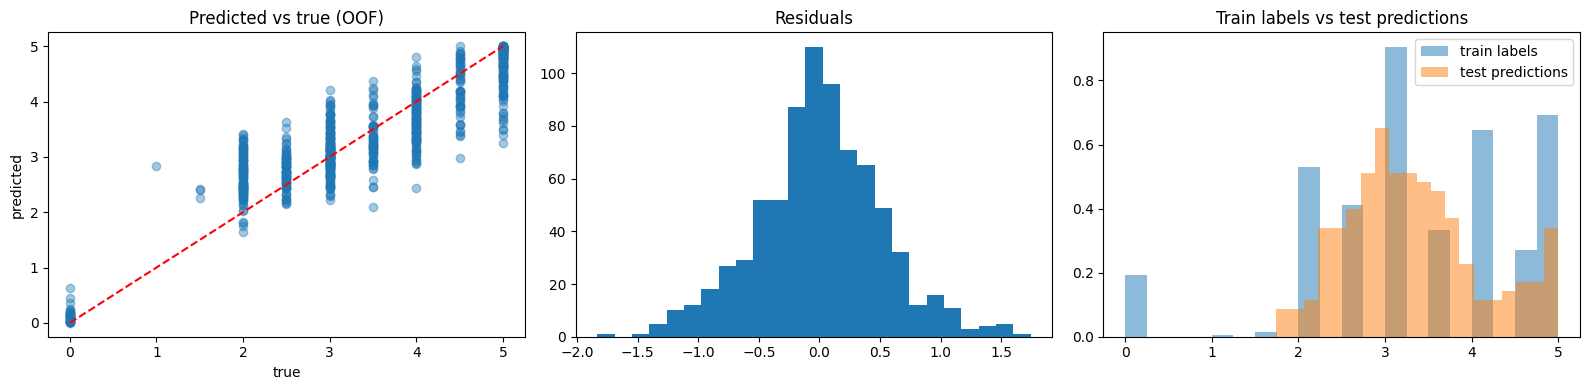

In [70]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error

names = ["SVR base", "Ridge base", "SVR large", "Ridge large", "SVR hubert", "Ridge hubert", "Layer-mix"]
rows = [(n, np.sqrt(np.mean((y - np.clip(o, 0, 5)) ** 2)), pearsonr(y, np.clip(o, 0, 5))[0])
        for n, o in zip(names, oof_list)]
rows.append(("Final blend", rmse_raw, pearsonr(y, blend_oof)[0]))
print(pd.DataFrame(rows, columns=["model", "RMSE", "Pearson"]).round(3).to_string(index=False))

print("\nFinal blend OOF:")
print("RMSE    :", rmse_raw)
print("Pearson :", pearsonr(y, blend_oof)[0])
print("Spearman:", spearmanr(y, blend_oof)[0])
print("MAE     :", mean_absolute_error(y, blend_oof))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(y, blend_oof, alpha=0.4); ax[0].plot([0, 5], [0, 5], "r--")
ax[0].set_xlabel("true"); ax[0].set_ylabel("predicted"); ax[0].set_title("Predicted vs true (OOF)")
ax[1].hist(y - blend_oof, bins=25); ax[1].set_title("Residuals")
ax[2].hist(y, bins=20, alpha=0.5, density=True, label="train labels")
ax[2].hist(preds, bins=20, alpha=0.5, density=True, label="test predictions")
ax[2].legend(); ax[2].set_title("Train labels vs test predictions")
plt.tight_layout(); plt.show()

In [71]:
feats      = np.load("wavlm_train_feats.npy");  test_feats   = np.load("wavlm_test_feats.npy")
feats_L    = np.load("wavlmL_train.npy");       test_feats_L = np.load("wavlmL_test.npy")
feats_H    = np.load("hubert_train.npy");       test_feats_H = np.load("hubert_test.npy")